In [1]:

# CODE 1: Install and import required libraries

!pip -q install pandas numpy matplotlib seaborn scikit-learn joblib

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")

# Create project folders
PROJECT_DIR = Path("/content/agriculture-yield-prediction")
OUTPUT_DIR = PROJECT_DIR / "outputs"

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Libraries imported successfully!")
print("Project folders created successfully!")
print("Project location:", PROJECT_DIR)


Libraries imported successfully!
Project folders created successfully!
Project location: /content/agriculture-yield-prediction


In [2]:

# CODE 2: Create an Agriculture Yield Dataset

import pandas as pd
import numpy as np

np.random.seed(42)

n = 1000

states = ["Uttar Pradesh", "Punjab", "Haryana", "Bihar", "Madhya Pradesh"]
crops = ["Wheat", "Rice", "Maize", "Sugarcane", "Cotton"]
soil_types = ["Alluvial", "Black", "Red", "Clay", "Loamy"]

df = pd.DataFrame({
    "State": np.random.choice(states, n),
    "Crop": np.random.choice(crops, n),
    "Soil_Type": np.random.choice(soil_types, n),
    "Rainfall_mm": np.random.uniform(400, 1500, n).round(2),
    "Temperature_C": np.random.uniform(18, 40, n).round(2),
    "Humidity_Percent": np.random.uniform(30, 90, n).round(2),
    "Fertilizer_kg_per_hectare": np.random.uniform(40, 250, n).round(2),
    "Area_Hectares": np.random.uniform(1, 100, n).round(2)
})

# Generate a simulated crop-yield target (tonnes per hectare)
crop_bonus = df["Crop"].map({
    "Wheat": 2.5,
    "Rice": 3.0,
    "Maize": 2.0,
    "Sugarcane": 5.0,
    "Cotton": 1.5
})

soil_bonus = df["Soil_Type"].map({
    "Alluvial": 1.0,
    "Black": 0.8,
    "Red": 0.2,
    "Clay": 0.4,
    "Loamy": 1.2
})

df["Yield_tonnes_per_hectare"] = (
    1.5
    + df["Rainfall_mm"] * 0.002
    - abs(df["Temperature_C"] - 28) * 0.04
    + df["Humidity_Percent"] * 0.008
    + df["Fertilizer_kg_per_hectare"] * 0.008
    + crop_bonus
    + soil_bonus
    + np.random.normal(0, 0.5, n)
).clip(lower=0.5).round(2)

# Save dataset
dataset_path = PROJECT_DIR / "agriculture_yield_dataset.csv"
df.to_csv(dataset_path, index=False)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)
print("Dataset saved at:", dataset_path)

display(df.head(10))


Dataset created successfully!
Dataset shape: (1000, 9)
Dataset saved at: /content/agriculture-yield-prediction/agriculture_yield_dataset.csv


,State,Crop,Soil_Type,Rainfall_mm,Temperature_C,Humidity_Percent,Fertilizer_kg_per_hectare,Area_Hectares,Yield_tonnes_per_hectare
0,Bihar,Sugarcane,Clay,1140.26,35.93,60.70,141.68,21.73,9.26
1,Madhya Pradesh,Sugarcane,Red,702.92,35.12,59.00,206.74,4.90,10.29
2,Haryana,Sugarcane,Black,736.94,34.74,52.97,161.06,74.39,9.81
3,Madhya Pradesh,Sugarcane,Alluvial,1267.88,22.13,80.35,111.83,82.93,11.43
4,Madhya Pradesh,Cotton,Loamy,891.06,19.94,38.72,210.10,96.82,7.03
5,Punjab,Cotton,Loamy,1278.22,33.38,60.34,90.04,89.09,7.61
6,Haryana,Rice,Alluvial,1304.66,26.10,33.72,87.12,60.45,9.02
7,Haryana,Wheat,Alluvial,1343.32,27.51,34.27,145.95,53.48,9.24
8,Haryana,Sugarcane,Black,1408.30,18.69,64.43,94.78,3.76,10.46
9,Madhya Pradesh,Rice,Red,874.08,23.71,63.96,41.91,25.42,7.72


In [3]:

# CODE 3: Explore Dataset Information

print("========== DATASET OVERVIEW ==========")

# Display number of rows and columns
print("\n1. Dataset Shape:")
print(df.shape)

# Display column names
print("\n2. Column Names:")
print(df.columns.tolist())

# Display data types and non-null counts
print("\n3. Dataset Information:")
df.info()

# Display statistical summary
print("\n4. Statistical Summary:")
display(df.describe())

# Display dataset memory and size
print("\n5. Total Records:", len(df))
print("6. Total Columns:", len(df.columns))

print("\nCode 3 executed successfully!")


========== DATASET OVERVIEW ==========

1. Dataset Shape:
(1000, 9)

2. Column Names:
['State', 'Crop', 'Soil_Type', 'Rainfall_mm', 'Temperature_C', 'Humidity_Percent', 'Fertilizer_kg_per_hectare', 'Area_Hectares', 'Yield_tonnes_per_hectare']

3. Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   State                      1000 non-null   object 
 1   Crop                       1000 non-null   object 
 2   Soil_Type                  1000 non-null   object 
 3   Rainfall_mm                1000 non-null   float64
 4   Temperature_C              1000 non-null   float64
 5   Humidity_Percent           1000 non-null   float64
 6   Fertilizer_kg_per_hectare  1000 non-null   float64
 7   Area_Hectares              1000 non-null   float64
 8   Yield_tonnes_per_hectare   1000 non-null   float64
dtypes: flo

,Rainfall_mm,Temperature_C,Humidity_Percent,Fertilizer_kg_per_hectare,Area_Hectares,Yield_tonnes_per_hectare
count,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,947.319690,28.844270,59.76287,144.053900,50.135840,8.283820
std,315.706063,6.330323,17.34373,60.549646,28.718088,1.543724
min,400.010000,18.000000,30.01000,40.820000,1.020000,4.640000
25%,685.442500,23.290000,44.91750,91.107500,25.230000,7.170000
50%,946.825000,28.760000,59.02000,143.465000,49.240000,8.110000
75%,1216.187500,34.237500,74.96750,195.360000,76.132500,9.205000
max,1497.600000,39.990000,89.93000,249.890000,99.920000,13.290000



5. Total Records: 1000
6. Total Columns: 9

Code 3 executed successfully!


In [4]:

# CODE 4: Check Missing Values in Dataset

print("========== MISSING VALUES ANALYSIS ==========")

# Count missing values in each column
missing_values = df.isnull().sum()

print("\nMissing values in each column:")
print(missing_values)

# Calculate total missing values
total_missing = df.isnull().sum().sum()

print("\nTotal missing values:", total_missing)

# Calculate percentage of missing values
missing_percentage = (df.isnull().mean() * 100).round(2)

print("\nMissing values percentage:")
print(missing_percentage)

# Display columns containing missing values
columns_with_missing = missing_values[missing_values > 0]

if len(columns_with_missing) == 0:
    print("\nDataset is clean: No missing values found!")
else:
    print("\nColumns containing missing values:")
    print(columns_with_missing)

print("\nCode 4 executed successfully!")


========== MISSING VALUES ANALYSIS ==========

Missing values in each column:
State                        0
Crop                         0
Soil_Type                    0
Rainfall_mm                  0
Temperature_C                0
Humidity_Percent             0
Fertilizer_kg_per_hectare    0
Area_Hectares                0
Yield_tonnes_per_hectare     0
dtype: int64

Total missing values: 0

Missing values percentage:
State                        0.0
Crop                         0.0
Soil_Type                    0.0
Rainfall_mm                  0.0
Temperature_C                0.0
Humidity_Percent             0.0
Fertilizer_kg_per_hectare    0.0
Area_Hectares                0.0
Yield_tonnes_per_hectare     0.0
dtype: float64

Dataset is clean: No missing values found!

Code 4 executed successfully!


In [5]:

# CODE 5: Detect and Remove Duplicate Records

print("========== DUPLICATE RECORDS ANALYSIS ==========")

# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("\nTotal duplicate rows:", duplicate_count)

# Display duplicate records if found
if duplicate_count > 0:
    print("\nDuplicate records found:")
    display(df[df.duplicated(keep=False)].head(10))

    # Remove duplicate rows
    df = df.drop_duplicates().reset_index(drop=True)

    print("\nDuplicate records removed successfully!")
else:
    print("\nNo duplicate records found!")

# Verify dataset after cleaning
print("\nDataset shape after cleaning:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

# Save cleaned dataset
dataset_path = PROJECT_DIR / "agriculture_yield_dataset.csv"
df.to_csv(dataset_path, index=False)

print("\nCleaned dataset saved successfully!")
print("Code 5 executed successfully!")


========== DUPLICATE RECORDS ANALYSIS ==========

Total duplicate rows: 0

No duplicate records found!

Dataset shape after cleaning: (1000, 9)
Remaining duplicate rows: 0

Cleaned dataset saved successfully!
Code 5 executed successfully!


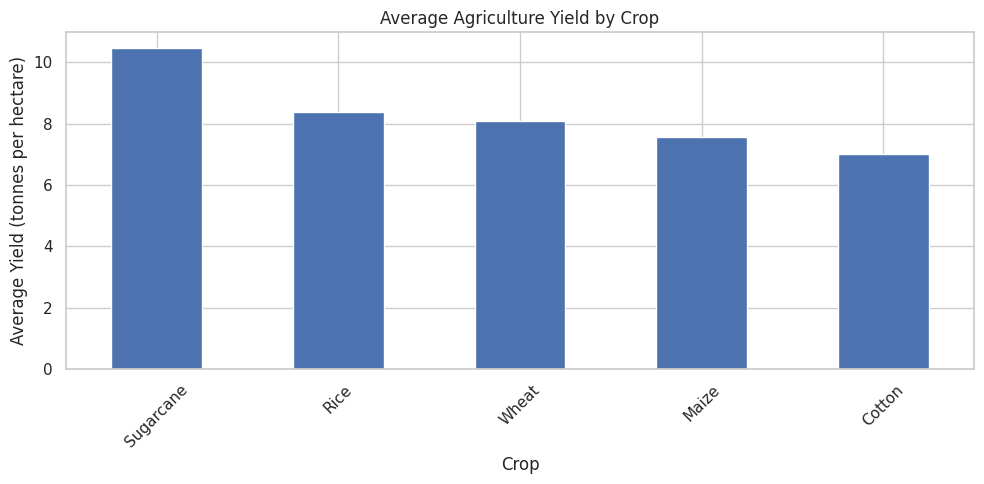

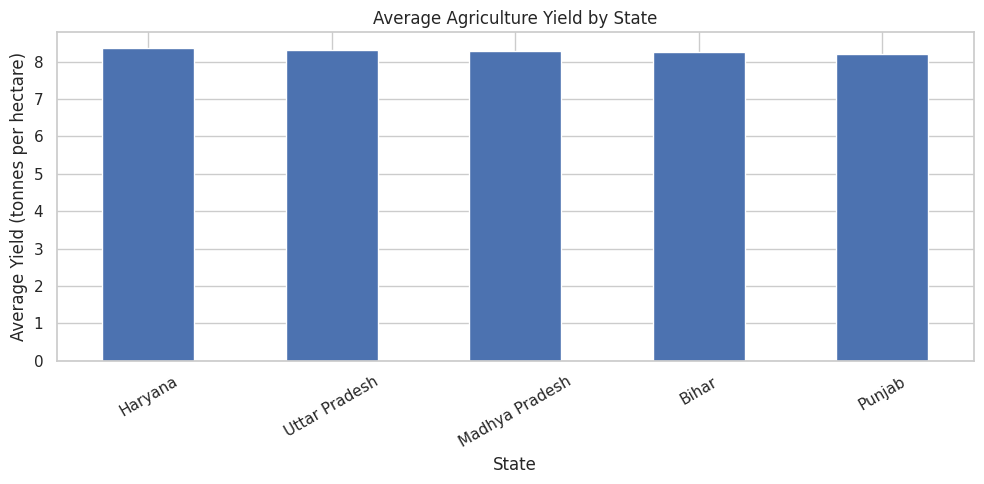

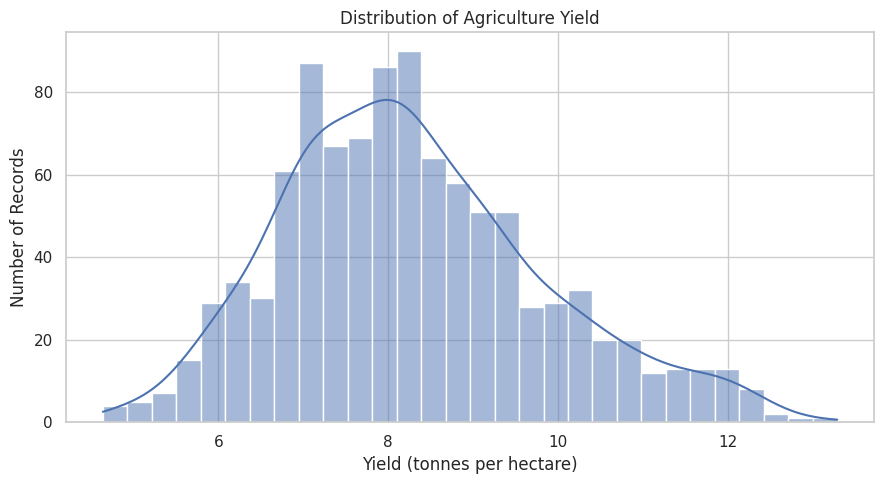

All three visualizations generated successfully!
Crop yield graph saved in: /content/agriculture-yield-prediction/outputs


In [6]:

# CODE 6: Agriculture Yield Data Visualization

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Average yield by crop
crop_yield = df.groupby("Crop")[
    "Yield_tonnes_per_hectare"
].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
crop_yield.plot(kind="bar")
plt.title("Average Agriculture Yield by Crop")
plt.xlabel("Crop")
plt.ylabel("Average Yield (tonnes per hectare)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Average yield by state
state_yield = df.groupby("State")[
    "Yield_tonnes_per_hectare"
].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
state_yield.plot(kind="bar")
plt.title("Average Agriculture Yield by State")
plt.xlabel("State")
plt.ylabel("Average Yield (tonnes per hectare)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 3. Distribution of crop yield
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df,
    x="Yield_tonnes_per_hectare",
    bins=30,
    kde=True
)
plt.title("Distribution of Agriculture Yield")
plt.xlabel("Yield (tonnes per hectare)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Save graphs for GitHub
plt.figure(figsize=(9, 5))
crop_yield.plot(kind="bar")
plt.title("Average Agriculture Yield by Crop")
plt.xlabel("Crop")
plt.ylabel("Yield (tonnes per hectare)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "crop_yield_comparison.png", dpi=300)
plt.close()

print("All three visualizations generated successfully!")
print("Crop yield graph saved in:", OUTPUT_DIR)


========== RAINFALL ANALYSIS ==========
Rainfall-Yield Correlation: 0.375
The sample data shows a positive relationship.


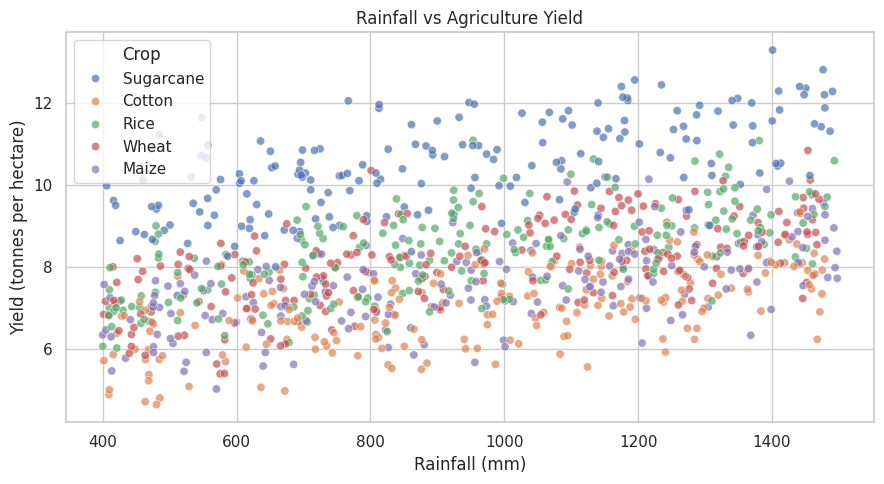


Rainfall Summary:


,Rainfall_mm,Yield_tonnes_per_hectare
count,1000.000000,1000.000000
mean,947.319690,8.283820
std,315.706063,1.543724
min,400.010000,4.640000
25%,685.442500,7.170000
50%,946.825000,8.110000
75%,1216.187500,9.205000
max,1497.600000,13.290000



Graph saved successfully!


In [7]:

# CODE 7: Analyze Rainfall vs Crop Yield

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation between rainfall and crop yield
correlation = df["Rainfall_mm"].corr(
    df["Yield_tonnes_per_hectare"]
)

print("========== RAINFALL ANALYSIS ==========")
print("Rainfall-Yield Correlation:", round(correlation, 3))

if correlation > 0:
    print("The sample data shows a positive relationship.")
elif correlation < 0:
    print("The sample data shows a negative relationship.")
else:
    print("No linear relationship found in the sample data.")

# Create scatter plot
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Rainfall_mm",
    y="Yield_tonnes_per_hectare",
    hue="Crop",
    alpha=0.7
)

plt.title("Rainfall vs Agriculture Yield")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Yield (tonnes per hectare)")
plt.tight_layout()

# Save graph
plt.savefig(
    OUTPUT_DIR / "rainfall_vs_yield.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Show rainfall and yield summary
print("\nRainfall Summary:")
display(
    df[["Rainfall_mm", "Yield_tonnes_per_hectare"]].describe()
)

print("\nGraph saved successfully!")


========== FERTILIZER ANALYSIS ==========
Fertilizer-Yield Correlation: 0.307

Average Yield by Fertilizer Level:


,Average_Yield
Fertilizer_Level,
Low,7.709597
Medium,8.196991
High,8.854419


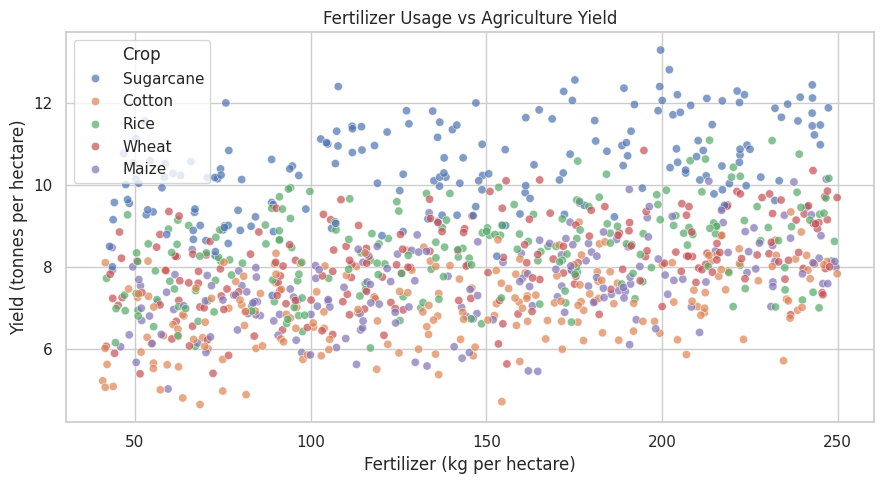

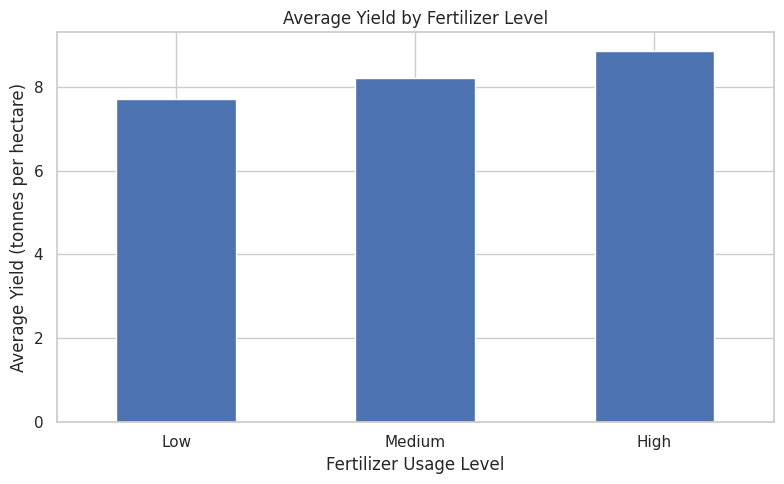


Fertilizer analysis completed successfully!


In [8]:

# CODE 8: Analyze Fertilizer Usage vs Crop Yield

import matplotlib.pyplot as plt
import seaborn as sns

print("========== FERTILIZER ANALYSIS ==========")

# Calculate correlation
correlation = df["Fertilizer_kg_per_hectare"].corr(
    df["Yield_tonnes_per_hectare"]
)

print("Fertilizer-Yield Correlation:", round(correlation, 3))

# Calculate average yield for fertilizer usage groups
df["Fertilizer_Level"] = pd.cut(
    df["Fertilizer_kg_per_hectare"],
    bins=[0, 100, 175, float("inf")],
    labels=["Low", "Medium", "High"]
)

fertilizer_analysis = df.groupby(
    "Fertilizer_Level",
    observed=False
)["Yield_tonnes_per_hectare"].mean()

print("\nAverage Yield by Fertilizer Level:")
display(fertilizer_analysis.to_frame("Average_Yield"))

# Create scatter plot
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Fertilizer_kg_per_hectare",
    y="Yield_tonnes_per_hectare",
    hue="Crop",
    alpha=0.7
)

plt.title("Fertilizer Usage vs Agriculture Yield")
plt.xlabel("Fertilizer (kg per hectare)")
plt.ylabel("Yield (tonnes per hectare)")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "fertilizer_vs_yield.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Create bar chart
plt.figure(figsize=(8, 5))
fertilizer_analysis.plot(kind="bar")

plt.title("Average Yield by Fertilizer Level")
plt.xlabel("Fertilizer Usage Level")
plt.ylabel("Average Yield (tonnes per hectare)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "fertilizer_level_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFertilizer analysis completed successfully!")


========== TEMPERATURE ANALYSIS ==========
Temperature-Yield Correlation: -0.026

Average Yield by Temperature Level:


,Average_Yield
Temperature_Level,
Low,8.286025
Moderate,8.318121
High,8.249253


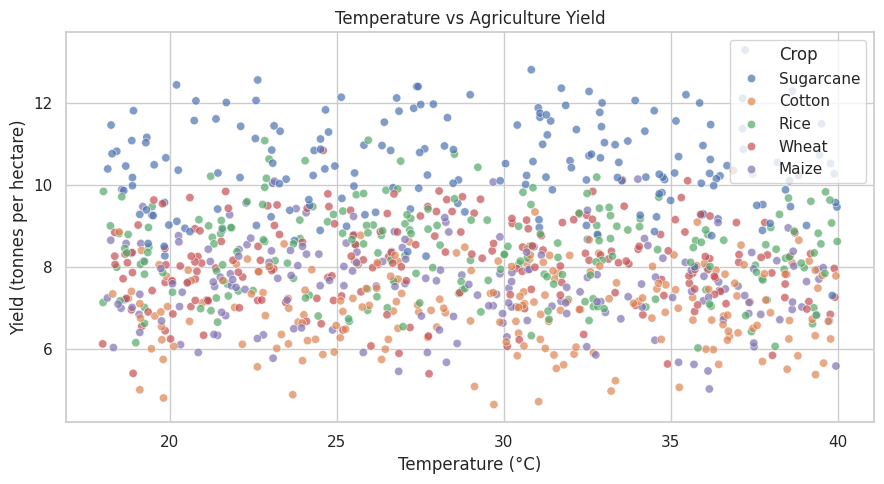

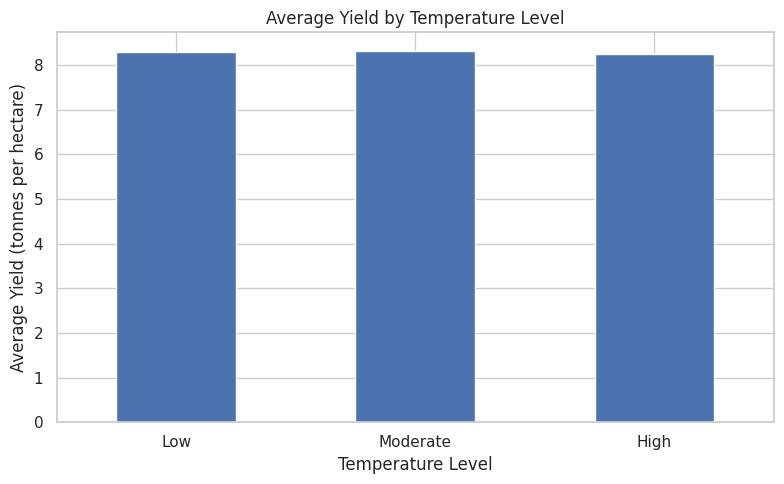


Temperature analysis completed successfully!
Graphs saved in: /content/agriculture-yield-prediction/outputs


In [9]:

# CODE 9: Analyze Temperature vs Agriculture Yield

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("========== TEMPERATURE ANALYSIS ==========")

# Calculate correlation between temperature and yield
correlation = df["Temperature_C"].corr(
    df["Yield_tonnes_per_hectare"]
)

print("Temperature-Yield Correlation:", round(correlation, 3))

# Create temperature categories
df["Temperature_Level"] = pd.cut(
    df["Temperature_C"],
    bins=[0, 25, 32, float("inf")],
    labels=["Low", "Moderate", "High"]
)

# Calculate average yield by temperature level
temperature_analysis = df.groupby(
    "Temperature_Level",
    observed=False
)["Yield_tonnes_per_hectare"].mean()

print("\nAverage Yield by Temperature Level:")
display(temperature_analysis.to_frame("Average_Yield"))

# Create scatter plot
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="Temperature_C",
    y="Yield_tonnes_per_hectare",
    hue="Crop",
    alpha=0.7
)

plt.title("Temperature vs Agriculture Yield")
plt.xlabel("Temperature (°C)")
plt.ylabel("Yield (tonnes per hectare)")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "temperature_vs_yield.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Create bar chart
plt.figure(figsize=(8, 5))

temperature_analysis.plot(kind="bar")

plt.title("Average Yield by Temperature Level")
plt.xlabel("Temperature Level")
plt.ylabel("Average Yield (tonnes per hectare)")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "temperature_level_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nTemperature analysis completed successfully!")
print("Graphs saved in:", OUTPUT_DIR)


========== CORRELATION ANALYSIS ==========

Correlation Matrix:


,Rainfall_mm,Temperature_C,Humidity_Percent,Fertilizer_kg_per_hectare,Area_Hectares,Yield_tonnes_per_hectare
Rainfall_mm,1.00,-0.03,-0.01,-0.01,-0.01,0.38
Temperature_C,-0.03,1.00,-0.04,0.05,-0.03,-0.03
Humidity_Percent,-0.01,-0.04,1.00,-0.03,0.01,0.07
Fertilizer_kg_per_hectare,-0.01,0.05,-0.03,1.00,0.00,0.31
Area_Hectares,-0.01,-0.03,0.01,0.00,1.00,0.05
Yield_tonnes_per_hectare,0.38,-0.03,0.07,0.31,0.05,1.00


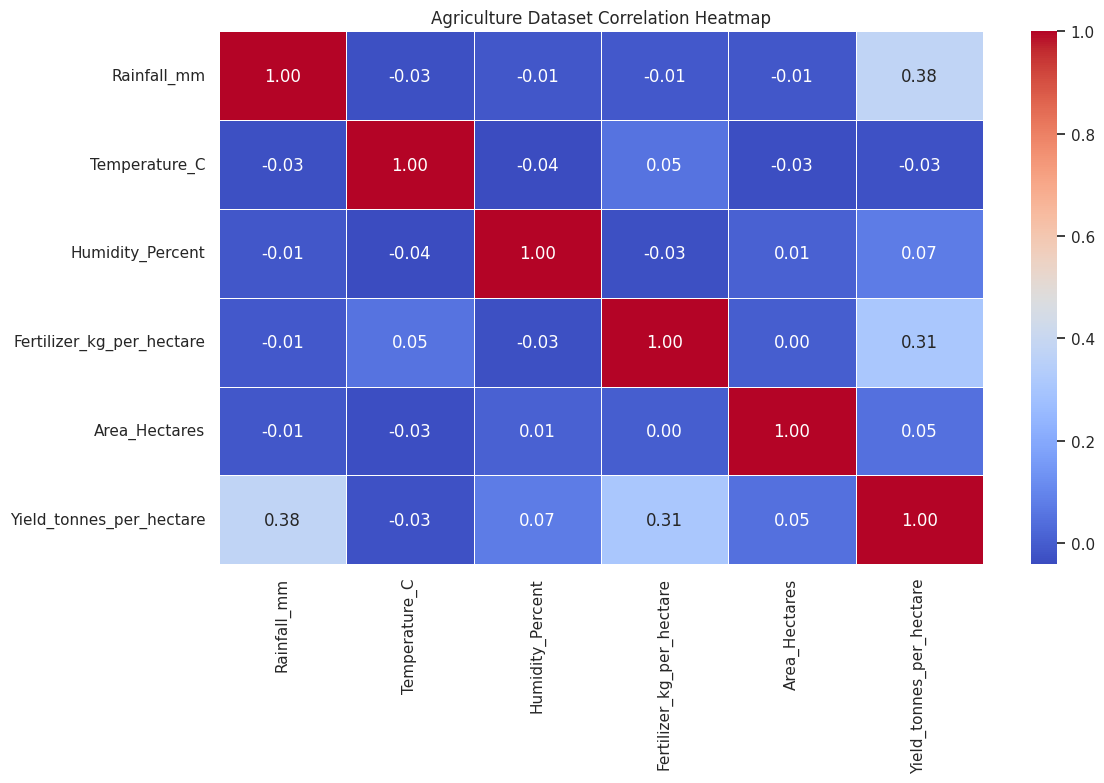


Feature Correlation with Crop Yield:


,Correlation_with_Yield
Rainfall_mm,0.375390
Fertilizer_kg_per_hectare,0.306903
Humidity_Percent,0.073513
Area_Hectares,0.046521
Temperature_C,-0.025553



Heatmap saved at: /content/agriculture-yield-prediction/outputs/correlation_heatmap.png
Code 10 executed successfully!


In [10]:

# CODE 10: Correlation Heatmap for Agriculture Dataset

import matplotlib.pyplot as plt
import seaborn as sns

print("========== CORRELATION ANALYSIS ==========")

# Select numerical columns only
numerical_df = df.select_dtypes(include="number")

# Calculate correlation matrix
correlation_matrix = numerical_df.corr()

print("\nCorrelation Matrix:")
display(correlation_matrix.round(2))

# Create heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Agriculture Dataset Correlation Heatmap")
plt.tight_layout()

# Save graph
heatmap_path = OUTPUT_DIR / "correlation_heatmap.png"

plt.savefig(
    heatmap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Identify features most correlated with yield
yield_correlation = correlation_matrix[
    "Yield_tonnes_per_hectare"
].drop("Yield_tonnes_per_hectare")

yield_correlation = yield_correlation.sort_values(
    ascending=False
)

print("\nFeature Correlation with Crop Yield:")
display(yield_correlation.to_frame("Correlation_with_Yield"))

print("\nHeatmap saved at:", heatmap_path)
print("Code 10 executed successfully!")


In [11]:

# CODE 11: Encode Categorical Features

from sklearn.preprocessing import LabelEncoder

print("========== CATEGORICAL DATA ENCODING ==========")

# Make a separate copy for encoded data
df_encoded = df.copy()

# Identify categorical columns
categorical_columns = df_encoded.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns found:")
print(categorical_columns)

# Encode categorical columns
label_encoders = {}

for column in categorical_columns:
    encoder = LabelEncoder()

    df_encoded[column] = encoder.fit_transform(
        df_encoded[column].astype(str)
    )

    label_encoders[column] = encoder

print("\nCategorical encoding completed!")

# Display original and encoded data
print("\nOriginal dataset preview:")
display(df.head(5))

print("\nEncoded dataset preview:")
display(df_encoded.head(5))

# Save encoded dataset
encoded_path = PROJECT_DIR / "agriculture_yield_encoded.csv"

df_encoded.to_csv(encoded_path, index=False)

print("\nEncoded dataset saved at:", encoded_path)
print("Encoded dataset shape:", df_encoded.shape)


========== CATEGORICAL DATA ENCODING ==========
Categorical columns found:
['State', 'Crop', 'Soil_Type', 'Fertilizer_Level', 'Temperature_Level']

Categorical encoding completed!

Original dataset preview:


,State,Crop,Soil_Type,Rainfall_mm,Temperature_C,Humidity_Percent,Fertilizer_kg_per_hectare,Area_Hectares,Yield_tonnes_per_hectare,Fertilizer_Level,Temperature_Level
0,Bihar,Sugarcane,Clay,1140.26,35.93,60.70,141.68,21.73,9.26,Medium,High
1,Madhya Pradesh,Sugarcane,Red,702.92,35.12,59.00,206.74,4.90,10.29,High,High
2,Haryana,Sugarcane,Black,736.94,34.74,52.97,161.06,74.39,9.81,Medium,High
3,Madhya Pradesh,Sugarcane,Alluvial,1267.88,22.13,80.35,111.83,82.93,11.43,Medium,Low
4,Madhya Pradesh,Cotton,Loamy,891.06,19.94,38.72,210.10,96.82,7.03,High,Low



Encoded dataset preview:


,State,Crop,Soil_Type,Rainfall_mm,Temperature_C,Humidity_Percent,Fertilizer_kg_per_hectare,Area_Hectares,Yield_tonnes_per_hectare,Fertilizer_Level,Temperature_Level
0,0,3,2,1140.26,35.93,60.70,141.68,21.73,9.26,2,0
1,2,3,4,702.92,35.12,59.00,206.74,4.90,10.29,0,0
2,1,3,1,736.94,34.74,52.97,161.06,74.39,9.81,2,0
3,2,3,0,1267.88,22.13,80.35,111.83,82.93,11.43,2,1
4,2,0,3,891.06,19.94,38.72,210.10,96.82,7.03,0,1



Encoded dataset saved at: /content/agriculture-yield-prediction/agriculture_yield_encoded.csv
Encoded dataset shape: (1000, 11)


In [12]:

# CODE 12: Feature Selection for Yield Prediction

print("========== FEATURE SELECTION ==========")

# Select input features for the model
feature_columns = [
    "State",
    "Crop",
    "Soil_Type",
    "Rainfall_mm",
    "Temperature_C",
    "Humidity_Percent",
    "Fertilizer_kg_per_hectare",
    "Area_Hectares"
]

# Define the target variable
target_column = "Yield_tonnes_per_hectare"

# Prepare input data and target
X = df_encoded[feature_columns].copy()
y = df_encoded[target_column].copy()

# Display selected features
print("\nInput Features (X):")
print(feature_columns)

print("\nTarget Variable (y):")
print(target_column)

# Display dimensions
print("\nInput Data Shape:", X.shape)
print("Target Data Shape:", y.shape)

# Display preview
print("\nInput Features Preview:")
display(X.head())

print("\nTarget Values Preview:")
display(y.head())

# Verify missing values
print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

print("\nFeature selection completed successfully!")


========== FEATURE SELECTION ==========

Input Features (X):
['State', 'Crop', 'Soil_Type', 'Rainfall_mm', 'Temperature_C', 'Humidity_Percent', 'Fertilizer_kg_per_hectare', 'Area_Hectares']

Target Variable (y):
Yield_tonnes_per_hectare

Input Data Shape: (1000, 8)
Target Data Shape: (1000,)

Input Features Preview:


,State,Crop,Soil_Type,Rainfall_mm,Temperature_C,Humidity_Percent,Fertilizer_kg_per_hectare,Area_Hectares
0,0,3,2,1140.26,35.93,60.70,141.68,21.73
1,2,3,4,702.92,35.12,59.00,206.74,4.90
2,1,3,1,736.94,34.74,52.97,161.06,74.39
3,2,3,0,1267.88,22.13,80.35,111.83,82.93
4,2,0,3,891.06,19.94,38.72,210.10,96.82



Target Values Preview:


,Yield_tonnes_per_hectare
0,9.26
1,10.29
2,9.81
3,11.43
4,7.03



Missing values in X: 0
Missing values in y: 0

Feature selection completed successfully!


In [13]:

# CODE 13: Split Data into Training and Testing Sets

from sklearn.model_selection import train_test_split

print("========== TRAIN-TEST SPLIT ==========")

# Split dataset: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset sizes
print("Original dataset size:", len(X))
print("Training dataset size:", len(X_train))
print("Testing dataset size:", len(X_test))

print("\nTraining Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# Verify split percentages
train_percentage = len(X_train) / len(X) * 100
test_percentage = len(X_test) / len(X) * 100

print("\nTraining Percentage:", round(train_percentage, 2), "%")
print("Testing Percentage:", round(test_percentage, 2), "%")

# Preview training data
print("\nTraining Data Preview:")
display(X_train.head())

print("\nTrain-test split completed successfully!")


========== TRAIN-TEST SPLIT ==========
Original dataset size: 1000
Training dataset size: 800
Testing dataset size: 200

Training Features Shape: (800, 8)
Testing Features Shape: (200, 8)

Training Target Shape: (800,)
Testing Target Shape: (200,)

Training Percentage: 80.0 %
Testing Percentage: 20.0 %

Training Data Preview:


,State,Crop,Soil_Type,Rainfall_mm,Temperature_C,Humidity_Percent,Fertilizer_kg_per_hectare,Area_Hectares
29,0,4,0,742.34,25.19,51.49,92.00,87.46
535,2,4,3,734.34,25.15,62.80,74.56,48.82
695,3,0,3,1143.63,36.63,30.72,90.16,19.11
557,2,1,1,1127.12,21.99,50.53,109.49,10.26
836,3,4,3,576.40,20.32,86.86,144.27,46.18



Train-test split completed successfully!


In [14]:

# CODE 14: Train Random Forest Regression Model

from sklearn.ensemble import RandomForestRegressor

print("========== MODEL TRAINING ==========")

# Initialize the Random Forest model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    max_depth=12,
    min_samples_split=2,
    n_jobs=-1
)

# Train the model using training data
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

# Display model configuration
print("\nModel Details:")
print(model)

# Generate predictions on test data
y_pred = model.predict(X_test)

print("\nFirst 10 actual yield values:")
print(y_test.head(10).to_list())

print("\nFirst 10 predicted yield values:")
print(y_pred[:10].round(2).tolist())

print("\nModel training and prediction completed!")


========== MODEL TRAINING ==========
Random Forest model trained successfully!

Model Details:
RandomForestRegressor(max_depth=12, n_jobs=-1, random_state=42)

First 10 actual yield values:
[7.45, 6.68, 7.82, 6.65, 7.03, 8.79, 7.06, 8.28, 5.84, 6.67]

First 10 predicted yield values:
[7.41, 6.82, 7.29, 7.8, 7.71, 7.41, 7.94, 7.45, 6.53, 6.59]

Model training and prediction completed!


In [15]:

# CODE 15: Evaluate Agriculture Yield Prediction Model

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

print("========== MODEL EVALUATION ==========")

# Predict yield on test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# Display results
print("\nMean Absolute Error (MAE):", round(mae, 3))
print("Mean Squared Error (MSE):", round(mse, 3))
print("Root Mean Squared Error (RMSE):", round(rmse, 3))
print("R2 Score:", round(r2, 3))

print("\n========== METRIC INTERPRETATION ==========")
print("MAE: Average absolute prediction error.")
print("MSE: Average squared prediction error.")
print("RMSE: Prediction error in yield units.")
print("R2: Proportion of target variation explained by the model.")

# Save evaluation metrics
metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],
    "Value": [mae, mse, rmse, r2]
})

metrics_path = OUTPUT_DIR / "model_evaluation_metrics.csv"
metrics.to_csv(metrics_path, index=False)

print("\nEvaluation metrics saved at:", metrics_path)
print("Model evaluation completed successfully!")


========== MODEL EVALUATION ==========

Mean Absolute Error (MAE): 0.559
Mean Squared Error (MSE): 0.474
Root Mean Squared Error (RMSE): 0.688
R2 Score: 0.827

========== METRIC INTERPRETATION ==========
MAE: Average absolute prediction error.
MSE: Average squared prediction error.
RMSE: Prediction error in yield units.
R2: Proportion of target variation explained by the model.

Evaluation metrics saved at: /content/agriculture-yield-prediction/outputs/model_evaluation_metrics.csv
Model evaluation completed successfully!


========== ACTUAL VS PREDICTED YIELD ==========

First 10 Prediction Comparisons:


,Actual_Yield,Predicted_Yield,Prediction_Error
0,7.45,7.41,0.04
1,6.68,6.82,-0.14
2,7.82,7.29,0.53
3,6.65,7.80,-1.15
4,7.03,7.71,-0.68
5,8.79,7.41,1.38
6,7.06,7.94,-0.88
7,8.28,7.45,0.83
8,5.84,6.53,-0.69
9,6.67,6.59,0.08


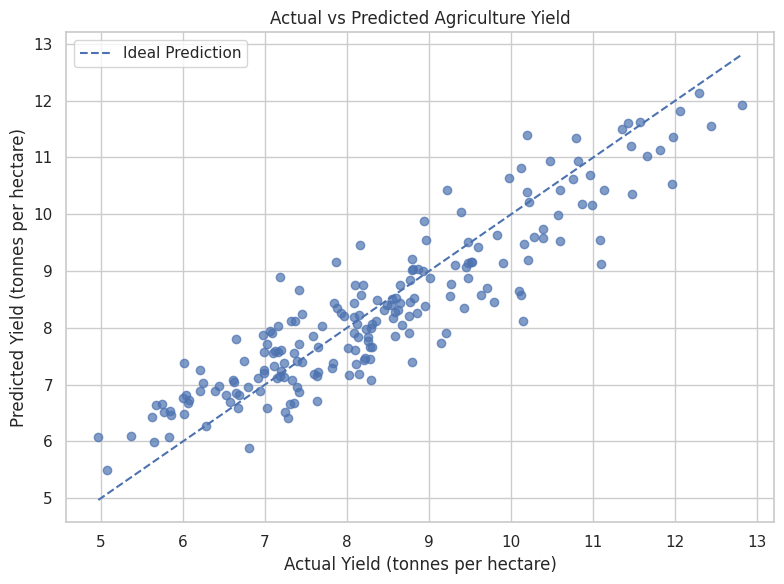


Comparison graph saved successfully!
Comparison data saved at: /content/agriculture-yield-prediction/outputs/prediction_comparison.csv


In [16]:

# CODE 16: Compare Actual and Predicted Agriculture Yield

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

print("========== ACTUAL VS PREDICTED YIELD ==========")

# Create a comparison DataFrame
comparison_df = pd.DataFrame({
    "Actual_Yield": y_test.to_numpy(),
    "Predicted_Yield": y_pred
})

# Calculate prediction error
comparison_df["Prediction_Error"] = (
    comparison_df["Actual_Yield"]
    - comparison_df["Predicted_Yield"]
)

# Display first 10 predictions
print("\nFirst 10 Prediction Comparisons:")
display(comparison_df.head(10).round(2))

# Plot actual vs predicted values
plt.figure(figsize=(8, 6))

plt.scatter(
    comparison_df["Actual_Yield"],
    comparison_df["Predicted_Yield"],
    alpha=0.7
)

# Draw ideal prediction line
min_value = min(
    comparison_df["Actual_Yield"].min(),
    comparison_df["Predicted_Yield"].min()
)

max_value = max(
    comparison_df["Actual_Yield"].max(),
    comparison_df["Predicted_Yield"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Ideal Prediction"
)

plt.title("Actual vs Predicted Agriculture Yield")
plt.xlabel("Actual Yield (tonnes per hectare)")
plt.ylabel("Predicted Yield (tonnes per hectare)")
plt.legend()
plt.tight_layout()

# Save graph
plt.savefig(
    OUTPUT_DIR / "actual_vs_predicted_yield.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save prediction comparison
comparison_path = OUTPUT_DIR / "prediction_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

print("\nComparison graph saved successfully!")
print("Comparison data saved at:", comparison_path)


========== FEATURE IMPORTANCE ANALYSIS ==========

Feature Importance Ranking:


,Feature,Importance
0,Crop,0.5435
1,Rainfall_mm,0.1916
2,Fertilizer_kg_per_hectare,0.1290
3,Humidity_Percent,0.0341
4,Soil_Type,0.0330
5,Temperature_C,0.0290
6,Area_Hectares,0.0263
7,State,0.0134


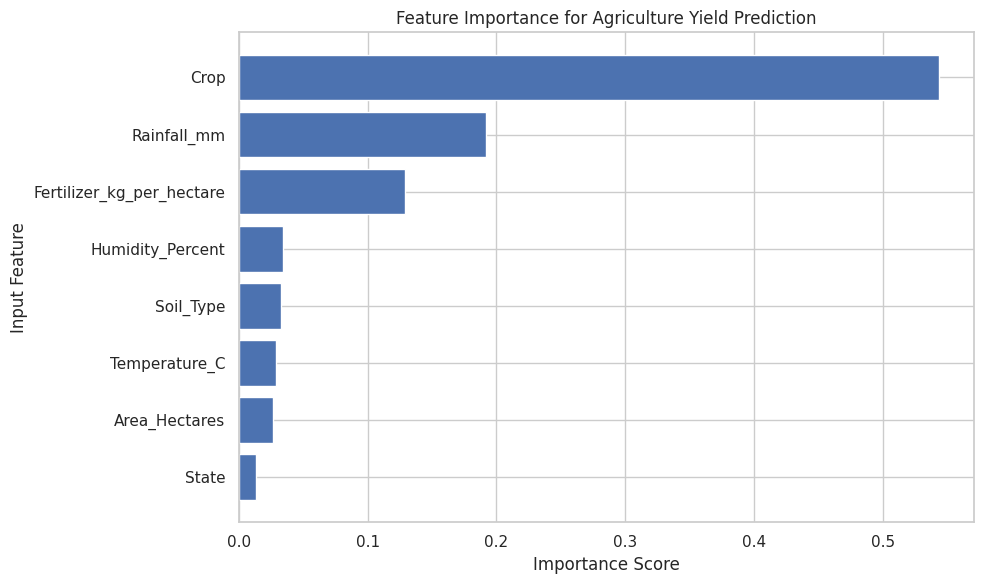


Feature importance graph saved at: /content/agriculture-yield-prediction/outputs/feature_importance.png
Feature importance table saved at: /content/agriculture-yield-prediction/outputs/feature_importance.csv

Code 17 completed successfully!


In [17]:

# CODE 17: Feature Importance Analysis

import pandas as pd
import matplotlib.pyplot as plt

print("========== FEATURE IMPORTANCE ANALYSIS ==========")

# Extract feature importance from trained model
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

# Sort features by importance
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display feature importance table
print("\nFeature Importance Ranking:")
display(importance_df.round(4))

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.title("Feature Importance for Agriculture Yield Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Input Feature")
plt.gca().invert_yaxis()
plt.tight_layout()

# Save graph
importance_path = OUTPUT_DIR / "feature_importance.png"

plt.savefig(
    importance_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Save importance values
importance_csv = OUTPUT_DIR / "feature_importance.csv"
importance_df.to_csv(importance_csv, index=False)

print("\nFeature importance graph saved at:", importance_path)
print("Feature importance table saved at:", importance_csv)
print("\nCode 17 completed successfully!")


In [18]:

# CODE 18: Save Trained Model and Encoders

import joblib
import json
from pathlib import Path

print("========== SAVING TRAINED MODEL ==========")

# Create model directory
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save trained Random Forest model
model_path = MODEL_DIR / "agriculture_yield_model.pkl"
joblib.dump(model, model_path)

# Save label encoders for reference
encoder_path = MODEL_DIR / "label_encoders.pkl"
joblib.dump(label_encoders, encoder_path)

# Save feature names and target information
model_info = {
    "model_name": "RandomForestRegressor",
    "project_name": "Data Analytics Framework for Agriculture Yield Prediction",
    "features": list(X_train.columns),
    "target": "Yield_tonnes_per_hectare",
    "target_unit": "tonnes per hectare",
    "n_estimators": 100,
    "random_state": 42
}

info_path = MODEL_DIR / "model_info.json"

with open(info_path, "w") as file:
    json.dump(model_info, file, indent=4)

print("Model saved successfully!")
print("Model file:", model_path)
print("Encoder file:", encoder_path)
print("Model information:", info_path)

# Verify saved files
print("\nSaved model files:")
for file_path in MODEL_DIR.iterdir():
    print(file_path.name, "-", file_path.stat().st_size, "bytes")

print("\nCode 18 completed successfully!")


========== SAVING TRAINED MODEL ==========
Model saved successfully!
Model file: /content/agriculture-yield-prediction/models/agriculture_yield_model.pkl
Encoder file: /content/agriculture-yield-prediction/models/label_encoders.pkl
Model information: /content/agriculture-yield-prediction/models/model_info.json

Saved model files:
agriculture_yield_model.pkl - 6478193 bytes
label_encoders.pkl - 1569 bytes
model_info.json - 474 bytes

Code 18 completed successfully!


In [19]:

# CODE 19: Load Saved Model and Test Prediction

import joblib
import pandas as pd
import numpy as np

print("========== SAVED MODEL TESTING ==========")

# Load the saved model
loaded_model = joblib.load(
    PROJECT_DIR / "models" / "agriculture_yield_model.pkl"
)

print("Saved model loaded successfully!")

# Select one sample from the test dataset
sample_input = X_test.iloc[[0]].copy()

# Predict agriculture yield
predicted_yield = loaded_model.predict(sample_input)[0]

# Get actual yield for comparison
actual_yield = y_test.iloc[0]

print("\nSample Input Features:")
display(sample_input)

print(
    "\nPredicted Yield:",
    round(predicted_yield, 2),
    "tonnes per hectare"
)

print(
    "Actual Sample Yield:",
    round(actual_yield, 2),
    "tonnes per hectare"
)

print(
    "Absolute Prediction Error:",
    round(abs(actual_yield - predicted_yield), 2),
    "tonnes per hectare"
)

# Save the test result
test_result = pd.DataFrame({
    "Actual_Yield": [actual_yield],
    "Predicted_Yield": [predicted_yield],
    "Absolute_Error": [abs(actual_yield - predicted_yield)]
})

test_path = OUTPUT_DIR / "saved_model_test_result.csv"
test_result.to_csv(test_path, index=False)

print("\nSaved model test result:", test_path)
print("Model loading and prediction test completed!")


========== SAVED MODEL TESTING ==========
Saved model loaded successfully!

Sample Input Features:


,State,Crop,Soil_Type,Rainfall_mm,Temperature_C,Humidity_Percent,Fertilizer_kg_per_hectare,Area_Hectares
521,4,0,0,1363.47,36.14,34.83,91.62,89.73



Predicted Yield: 7.41 tonnes per hectare
Actual Sample Yield: 7.45 tonnes per hectare
Absolute Prediction Error: 0.04 tonnes per hectare

Saved model test result: /content/agriculture-yield-prediction/outputs/saved_model_test_result.csv
Model loading and prediction test completed!


In [20]:

# CODE 19: Load Saved Model and Test Prediction

import joblib
import pandas as pd
import numpy as np

print("========== SAVED MODEL TESTING ==========")

# Load the saved model
loaded_model = joblib.load(
    PROJECT_DIR / "models" / "agriculture_yield_model.pkl"
)

print("Saved model loaded successfully!")

# Select one sample from the test dataset
sample_input = X_test.iloc[[0]].copy()

# Predict agriculture yield
predicted_yield = loaded_model.predict(sample_input)[0]

# Get actual yield for comparison
actual_yield = y_test.iloc[0]

print("\nSample Input Features:")
display(sample_input)

print(
    "\nPredicted Yield:",
    round(predicted_yield, 2),
    "tonnes per hectare"
)

print(
    "Actual Sample Yield:",
    round(actual_yield, 2),
    "tonnes per hectare"
)

print(
    "Absolute Prediction Error:",
    round(abs(actual_yield - predicted_yield), 2),
    "tonnes per hectare"
)

# Save the test result
test_result = pd.DataFrame({
    "Actual_Yield": [actual_yield],
    "Predicted_Yield": [predicted_yield],
    "Absolute_Error": [abs(actual_yield - predicted_yield)]
})

test_path = OUTPUT_DIR / "saved_model_test_result.csv"
test_result.to_csv(test_path, index=False)

print("\nSaved model test result:", test_path)
print("Model loading and prediction test completed!")


========== SAVED MODEL TESTING ==========
Saved model loaded successfully!

Sample Input Features:


,State,Crop,Soil_Type,Rainfall_mm,Temperature_C,Humidity_Percent,Fertilizer_kg_per_hectare,Area_Hectares
521,4,0,0,1363.47,36.14,34.83,91.62,89.73



Predicted Yield: 7.41 tonnes per hectare
Actual Sample Yield: 7.45 tonnes per hectare
Absolute Prediction Error: 0.04 tonnes per hectare

Saved model test result: /content/agriculture-yield-prediction/outputs/saved_model_test_result.csv
Model loading and prediction test completed!


In [21]:

# CODE 20: Prepare Complete Project for GitHub

import os
import json
import shutil
import zipfile
from pathlib import Path

print("========== FINAL PROJECT PREPARATION ==========")

# Ensure project folders exist
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save the latest dataset
df.to_csv(
    PROJECT_DIR / "agriculture_yield_dataset.csv",
    index=False
)

# Save the encoded dataset
df_encoded.to_csv(
    PROJECT_DIR / "agriculture_yield_encoded.csv",
    index=False
)

# Save model and encoders again
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    model,
    MODEL_DIR / "agriculture_yield_model.pkl"
)

joblib.dump(
    label_encoders,
    MODEL_DIR / "label_encoders.pkl"
)

# Save model information
model_info = {
    "project_name": "Data Analytics Framework for Agriculture Yield Prediction",
    "model": "RandomForestRegressor",
    "features": list(X_train.columns),
    "target": "Yield_tonnes_per_hectare",
    "target_unit": "tonnes per hectare",
    "dataset_type": "Simulated educational dataset"
}

with open(MODEL_DIR / "model_info.json", "w") as f:
    json.dump(model_info, f, indent=4)

# Create README documentation
readme_content = """
# Data Analytics Framework for Agriculture Yield Prediction

## Project Overview
This project demonstrates an agriculture yield prediction workflow
using Python, data analytics, visualization, and machine learning.

## Technologies Used
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Joblib
- Google Colab

## Workflow
1. Dataset creation
2. Dataset exploration
3. Missing value and duplicate checks
4. Exploratory data analysis and visualization
5. Categorical data encoding
6. Feature selection
7. Train-test split
8. Random Forest regression
9. Model evaluation using MAE, MSE, RMSE and R2
10. Feature importance and prediction visualization
11. Model saving and loading

## Dataset
The dataset used in this educational project is simulated.
It is not official agricultural data and must not be used to
make real farming or financial decisions.

## Target Variable
Yield_tonnes_per_hectare

## How to Run
Open the notebook in Google Colab and execute the cells
in order from Code 1 to Code 20.

## Model
RandomForestRegressor from scikit-learn.

## Limitations
The model's results reflect the simulated dataset only.
Real-world evaluation requires reliable agricultural data.

## Author
Ayush Dixit
"""

with open(PROJECT_DIR / "README.md", "w") as f:
    f.write(readme_content.strip() + "\n")

# Create requirements file
requirements_content = """
pandas
numpy
matplotlib
seaborn
scikit-learn
joblib
"""

with open(PROJECT_DIR / "requirements.txt", "w") as f:
    f.write(requirements_content.strip() + "\n")

# Copy the Colab notebook into the project folder if available
notebook_source = Path("/content/agriculture_yield_prediction.ipynb")

if notebook_source.exists():
    shutil.copy2(
        notebook_source,
        PROJECT_DIR / "agriculture_yield_prediction.ipynb"
    )
    print("Notebook copied into project folder.")
else:
    print(
        "Notebook file not found at the expected path. "
        "Download it separately from Colab using "
        "File > Download > Download .ipynb."
    )

# Create ZIP archive
zip_path = Path("/content/agriculture-yield-prediction.zip")

if zip_path.exists():
    zip_path.unlink()

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zipf:
    for file_path in PROJECT_DIR.rglob("*"):
        if file_path.is_file():
            zipf.write(
                file_path,
                file_path.relative_to(PROJECT_DIR.parent)
            )

print("\n========== PROJECT FILES ==========")

for file_path in sorted(PROJECT_DIR.rglob("*")):
    if file_path.is_file():
        print(file_path.relative_to(PROJECT_DIR))

print("\nProject folder:", PROJECT_DIR)
print("ZIP archive:", zip_path)
print("ZIP size:", round(zip_path.stat().st_size / 1024, 2), "KB")

print("\nPROJECT PREPARATION COMPLETED!")


========== FINAL PROJECT PREPARATION ==========
Notebook file not found at the expected path. Download it separately from Colab using File > Download > Download .ipynb.

========== PROJECT FILES ==========
README.md
agriculture_yield_dataset.csv
agriculture_yield_encoded.csv
models/agriculture_yield_model.pkl
models/label_encoders.pkl
models/model_info.json
outputs/actual_vs_predicted_yield.png
outputs/correlation_heatmap.png
outputs/crop_yield_comparison.png
outputs/feature_importance.csv
outputs/feature_importance.png
outputs/fertilizer_level_comparison.png
outputs/fertilizer_vs_yield.png
outputs/model_evaluation_metrics.csv
outputs/prediction_comparison.csv
outputs/rainfall_vs_yield.png
outputs/saved_model_test_result.csv
outputs/temperature_level_comparison.png
outputs/temperature_vs_yield.png
requirements.txt

Project folder: /content/agriculture-yield-prediction
ZIP archive: /content/agriculture-yield-prediction.zip
ZIP size: 4389.12 KB

PROJECT PREPARATION COMPLETED!


In [22]:
import pandas as pd
from google.colab import files

print("========================================")
print("1. VERIFYING MODEL EVALUATION METRICS")
print("========================================")
metrics = pd.read_csv('/content/agriculture-yield-prediction/outputs/model_evaluation_metrics.csv')
display(metrics)

print("\n========================================")
print("2. VERIFYING SAVED MODEL TEST RESULT")
print("========================================")
test_res = pd.read_csv('/content/agriculture-yield-prediction/outputs/saved_model_test_result.csv')
display(test_res)

print("\n========================================")
print("3. DOWNLOADING ZIP ARCHIVE")
print("========================================")
files.download('/content/agriculture-yield-prediction.zip')

1. VERIFYING MODEL EVALUATION METRICS


,Metric,Value
0,MAE,0.559265
1,MSE,0.473895
2,RMSE,0.688401
3,R2 Score,0.827121



2. VERIFYING SAVED MODEL TEST RESULT


,Actual_Yield,Predicted_Yield,Absolute_Error
0,7.45,7.406418,0.043582



3. DOWNLOADING ZIP ARCHIVE


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>